# QSVM: Section 7, diagnostic experiments (consolidated)

All nine diagnostic experiments of Section 7 of the paper, in the order they appear there. Run it top to bottom.
Expected total runtime on the reference machine: about 40 minutes (Diagnostic 2 alone is about 15 minutes, Diagnostic 9 about 16).

| # | Diagnostic (paper) | Original notebook / name there | Output files (`results_diagnostics/`) |
|---|---|---|---|
| 1 | Composition control | `Step4_Diagnostics`, Experiment 1 | `exp1_*.csv` |
| 2 | Dimension-matched controls | `Step4_Diagnostics`, Experiment 2 | `exp2_*.csv` |
| 3 | Anchor-aware augmentation | `Step4_Diagnostics`, Experiment 3 | `exp3_*.csv` |
| 4 | Residual-feature test | `Step4_Diagnostics`, Experiment 4 | `exp4_*.csv` |
| 5 | PCA / dispersion ablation | `EXPERIMENT_5` | `exp5_*.csv` |
| 6 | Pooled-vector collision analysis | `Steve_Notes_nested`, section 4 | `pooled_feature_duplicate*.csv` |
| 7 | Continuous-outcome analysis | `Step4_Diagnostics`, Experiment 8 | `exp8_regression.csv` |
| 8 | Learning curves | `Step4_Diagnostics`, Experiment 9 | `exp9_learning_curves.*` |
| 9 | Selection-aware null test | `EXPERIMENT_10` | `exp10_*` |

File names keep the experiment numbers of the original notebooks, so they differ from the paper's numbering for Diagnostics 7, 8 and 9.

## How this notebook was assembled

**The experiment code was not modified.** Every code cell below is copied unchanged from the original notebooks, and the seed is
`RANDOM_SEED = 42` everywhere. The remaining random draws in that code (`default_rng(...)`, `random_state=...`) carry their own
explicit seeds, so moving a section to a different position does not change any number.

* **Section 0 is shared.** Configuration, data, similarity groups, derived representations and the nested-CV machinery are taken once
  from `Step4_Diagnostics`. The other notebooks carried identical copies of the data and group code.
* **Diagnostics 5 and 9 define their own versions** of a few names (`REPS`, `nested_cv_classical`, `_transform`, ...). Those definition
  cells are kept as they were, collapsed, at the start of each section.
* **Diagnostic 5 overwrites `REPS`**, which Diagnostics 7 and 8 read. Diagnostic 7 therefore starts by re-running the original `REPS`
  definition cell.

**Three things differ from simply concatenating the files**
1. The older Experiment 2 cell of `Step4_Diagnostics` (one random projection) is left out. The cell with five seeded projections, the one the paper describes, is used.
2. In the combined-table cell (after Diagnostic 4), the row-order list `order` named `rand_proj_5`, a representation that no longer exists once Experiment 2 uses five projections. It now lists `rand_1` to `rand_5`. This only changes which rows are displayed.
3. Diagnostic 6 runs over the 8 representations of `Steve_Notes_nested`; see the note in its section.

## 0. Shared setup

### 0.1 Configuration and imports

In [3]:
import os
import json
import time
import itertools
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import spearmanr
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, StratifiedGroupKFold
from sklearn.svm import SVC
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import (balanced_accuracy_score, accuracy_score, matthews_corrcoef,
                             mean_absolute_error, mean_squared_error)
from sklearn.metrics.pairwise import rbf_kernel, linear_kernel, polynomial_kernel

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

N_SPLITS_OUTER, N_REPEATS_OUTER, N_SPLITS_INNER = 5, 20, 4

CLASSICAL_GRIDS = {
    'linear': {'C': [0.1, 1, 10]},
    'rbf':    {'C': [0.1, 1, 10], 'gamma': ['scale', 0.01, 0.1, 1]},
    'poly':   {'C': [0.1, 1, 10], 'degree': [2, 3], 'gamma': ['scale', 0.1, 1], 'coef0': [0.0, 1.0]},
}
REGRESSION_GRIDS = {
    'linear': {'alpha': [0.01, 0.1, 1, 10]},
    'rbf':    {'alpha': [0.01, 0.1, 1, 10], 'gamma': ['scale', 0.01, 0.1, 1]},
}
MODELS = ['linear', 'rbf', 'poly']   # classical kernel families used throughout

OUTDIR = 'results_diagnostics'
os.makedirs(OUTDIR, exist_ok=True)
print(f'outer {N_SPLITS_OUTER}x{N_REPEATS_OUTER} = {N_SPLITS_OUTER*N_REPEATS_OUTER} folds, inner {N_SPLITS_INNER}')

outer 5x20 = 100 folds, inner 4


### 0.2 Data, sequences and similarity groups

In [4]:
_lab = pd.read_excel('Docking_high_low_energy_labels.xlsx', sheet_name='Results')
_lab = _lab.dropna(subset=['Sequence Epitope)']).reset_index(drop=True)
sequences = _lab['Sequence Epitope)'].astype(str).str.strip().tolist()
y = (_lab['Otsu Class theshold -77.8'] == 'Strong').astype(int).values
E = _lab['Binding Energy '].values  # continuous docking energy, for Experiment 8

full45 = pd.read_csv('zscaled_5_45.csv', index_col=0).values  # (80, 45): z_p_k, p=1..9, k=1..5
assert full45.shape == (len(y), 45)

print(f'{len(y)} peptides, class balance {np.bincount(y)}, '
      f'binding energy range [{E.min():.1f}, {E.max():.1f}]')

80 peptides, class balance [42 38], binding energy range [-108.5, -48.5]


/home/luispabloelchido/miniconda3/envs/QML/lib/python3.11/site-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


In [5]:
# sequence-redundancy groups -- identical construction to the Step-3 notebook
K_SHARED, IDENTITY_THRESH = 5, 7 / 9


def similarity_edges(sequences, k_shared=K_SHARED, identity_thresh=IDENTITY_THRESH):
    n, L = len(sequences), len(sequences[0])
    kmers = [{s[i:i + k_shared] for i in range(L - k_shared + 1)} for s in sequences]
    edges = []
    for i in range(n):
        for j in range(i + 1, n):
            shared = bool(kmers[i] & kmers[j])
            identity = sum(a == b for a, b in zip(sequences[i], sequences[j])) / L
            if shared or identity >= identity_thresh:
                edges.append((i, j))
    return edges


def build_groups_unionfind(n, edges):
    parent = list(range(n))

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a

    for i, j in edges:
        ri, rj = find(i), find(j)
        if ri != rj:
            parent[ri] = rj
    raw = [find(i) for i in range(n)]
    remap = {g: k for k, g in enumerate(sorted(set(raw)))}
    return np.array([remap[g] for g in raw])


n_pep = len(sequences)
edges = similarity_edges(sequences)
groups = build_groups_unionfind(n_pep, edges)

adj = coo_matrix((np.ones(len(edges)),
                  (np.array([e[0] for e in edges]), np.array([e[1] for e in edges]))),
                 shape=(n_pep, n_pep))
n_cc, cc_labels = connected_components(adj, directed=False)
assert len(set(zip(groups, cc_labels))) == len(set(groups)) == len(set(cc_labels))
print(f'{len(np.unique(groups))} groups (verified against scipy connected components), '
      f'{pd.Series(groups).value_counts().eq(1).sum()} singletons')

43 groups (verified against scipy connected components), 25 singletons


### 0.3 Derived representations

In [6]:
def mean_from_full45(X45, exclude_positions=()):
    """Mean z-scale over the 9 positions, optionally excluding some (0-indexed positions)."""
    keep = [p for p in range(9) if p not in exclude_positions]
    out = np.zeros((X45.shape[0], 5))
    for k in range(5):
        cols = [p * 5 + k for p in keep]
        out[:, k] = X45[:, cols].mean(axis=1)
    return out


mean_z = mean_from_full45(full45)                       # z_i, Eq 1/3 in Steve's note
mean_z7 = mean_from_full45(full45, exclude_positions=(1, 8))  # excludes position 2 (idx1), position 9 (idx8)
pos2, pos9 = full45[:, 5:10], full45[:, 40:45]

AAS = sorted(set(''.join(sequences)))
comp_freq_20 = np.zeros((n_pep, len(AAS)))
for i, s in enumerate(sequences):
    for a in s:
        comp_freq_20[i, AAS.index(a)] += 1
comp_freq_20 /= len(sequences[0])

anchor_raw_15 = np.hstack([mean_z7, pos2, pos9])
anchor_residual_15 = np.hstack([mean_z, pos2 - mean_z, pos9 - mean_z])

mean_broadcast = np.zeros((n_pep, 45))
for p in range(9):
    mean_broadcast[:, p * 5:(p * 5 + 5)] = mean_z
R_i = full45 - mean_broadcast                            # R_ip, Eq 3
residual_50 = np.hstack([mean_z, R_i])                   # (z_i, R_i), Eq 3

resid_check = np.abs(np.stack([R_i[:, [p * 5 + k for p in range(9)]].sum(axis=1)
                               for k in range(5)])).max()
print(f'sanity: max |sum of residuals over 9 positions| = {resid_check:.2e} (should be ~0)')

for name, X in [('mean_z', mean_z), ('comp_freq_20', comp_freq_20), ('full45', full45),
                 ('anchor_raw_15', anchor_raw_15), ('anchor_residual_15', anchor_residual_15),
                 ('residual_50', residual_50)]:
    assert np.isfinite(X).all(), name
    print(f'  {name:20s} {X.shape}')


def make_random_projection(n_features_in, n_out=5, seed=2026):
    """A FIXED matrix, generated once, never refit -- the non-biological, non-learned control."""
    rng = np.random.default_rng(seed)
    return rng.normal(size=(n_features_in, n_out)) / np.sqrt(n_features_in)


RAND_R = make_random_projection(45, 5)
RAND_R_1= make_random_projection(45, 5,2000)
RAND_R_2 = make_random_projection(45, 5,2098)
RAND_R_3 = make_random_projection(45, 5,2572)
RAND_R_4 = make_random_projection(45, 5,23)
RAND_R_5 = make_random_projection(45, 5,42)

sanity: max |sum of residuals over 9 positions| = 4.66e-15 (should be ~0)
  mean_z               (80, 5)
  comp_freq_20         (80, 20)
  full45               (80, 45)
  anchor_raw_15        (80, 15)
  anchor_residual_15   (80, 15)
  residual_50          (80, 50)


### 0.4 Nested-CV machinery

In [7]:
def fit_scale(X_train, X_test):
    scaler = MinMaxScaler(feature_range=(-np.pi, np.pi))
    scaler.fit(X_train)
    return scaler.transform(X_train), scaler.transform(X_test)


def transform_random_projection(X_train, X_test, R):
    mu, sd = X_train.mean(0), X_train.std(0)
    sd = np.where(sd < 1e-12, 1.0, sd)
    return ((X_train - mu) / sd) @ R, ((X_test - mu) / sd) @ R


def transform_pca(X_train, X_test, n_components=5):
    scaler = StandardScaler().fit(X_train)
    pca = PCA(n_components=n_components, random_state=RANDOM_SEED).fit(scaler.transform(X_train))
    return pca.transform(scaler.transform(X_train)), pca.transform(scaler.transform(X_test))


def _transform(rep, tr_idx, te_idx):
    """rep is either a static (N,d) array, or a callable(tr_idx, te_idx) -> (Xtr, Xte)."""
    if callable(rep):
        return rep(tr_idx, te_idx)
    Xtr, Xte = fit_scale(rep[tr_idx], rep[te_idx])
    return Xtr, Xte


REPS = {
    'mean_z': mean_z, 'comp_freq_20': comp_freq_20, 'full45': full45,
    'anchor_raw_15': anchor_raw_15, 'anchor_residual_15': anchor_residual_15,
    'residual_50': residual_50,
    'rand_proj_5': lambda tr, te: transform_random_projection(
        full45[tr], full45[te], RAND_R),
    'rand_1': lambda tr, te: transform_random_projection(
    full45[tr], full45[te], RAND_R_1
    ),

    'rand_2': lambda tr, te: transform_random_projection(
        full45[tr], full45[te], RAND_R_2
    ),

    'rand_3': lambda tr, te: transform_random_projection(
        full45[tr], full45[te], RAND_R_3
    ),

    'rand_4': lambda tr, te: transform_random_projection(
        full45[tr], full45[te], RAND_R_4
    ),

    'rand_5': lambda tr, te: transform_random_projection(
        full45[tr], full45[te], RAND_R_5
    ),
    'pca_5': lambda tr, te: transform_pca(full45[tr], full45[te], n_components=5),
}

In [8]:
def make_outer_splits(y, groups=None, n_splits=N_SPLITS_OUTER, n_repeats=N_REPEATS_OUTER,
                      random_state=RANDOM_SEED):
    if groups is None:
        return list(RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats,
                                            random_state=random_state).split(np.zeros(len(y)), y))
    splits = []
    for r in range(n_repeats):
        sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=random_state + r)
        splits.extend(sgkf.split(np.zeros(len(y)), y, groups))
    return splits


def _inner_splits(y_tr, groups_tr, fold_i):
    if groups_tr is None:
        return list(StratifiedKFold(n_splits=N_SPLITS_INNER, shuffle=True,
                                    random_state=RANDOM_SEED + fold_i).split(np.zeros(len(y_tr)), y_tr))
    return list(StratifiedGroupKFold(n_splits=N_SPLITS_INNER, shuffle=True,
                                     random_state=RANDOM_SEED + fold_i)
                .split(np.zeros(len(y_tr)), y_tr, groups_tr))


def _param_combinations(grid):
    keys = list(grid)
    return [dict(zip(keys, vals)) for vals in itertools.product(*(grid[k] for k in keys))]


def _resolve_gamma(gamma, Xs):
    if gamma == 'scale':
        return 1.0 / (Xs.shape[1] * Xs.var()) if Xs.var() > 0 else 1.0
    return gamma


def _fit_svc(kernel_name, Xtr, ytr, params):
    gamma = _resolve_gamma(params.get('gamma', 'scale'), Xtr)
    if kernel_name == 'linear':
        clf = SVC(kernel='linear', C=params['C'])
    elif kernel_name == 'rbf':
        clf = SVC(kernel='rbf', C=params['C'], gamma=gamma)
    else:
        clf = SVC(kernel='poly', C=params['C'], degree=params['degree'], gamma=gamma, coef0=params['coef0'])
    return clf.fit(Xtr, ytr)


def _build_gram(kernel_name, Xa, Xb, params, Xtr):
    gamma = _resolve_gamma(params.get('gamma', 'scale'), Xtr)
    if kernel_name == 'linear':
        return linear_kernel(Xa, Xb)
    if kernel_name == 'rbf':
        return rbf_kernel(Xa, Xb, gamma=gamma)
    return polynomial_kernel(Xa, Xb, degree=params['degree'], gamma=gamma, coef0=params['coef0'])


def kernel_diagnostics(K, y_pm1):
    m = len(y_pm1)
    S = y_pm1 @ K @ y_pm1 - np.trace(K)
    Q = np.sum(K ** 2) - np.sum(np.diag(K) ** 2)
    kta = (m + S) / (m * np.sqrt(m + Q))
    H = np.eye(m) - np.ones((m, m)) / m
    Kc, yyTc = H @ K @ H, H @ np.outer(y_pm1, y_pm1).astype(float) @ H
    cka = np.sum(Kc * yyTc) / (np.linalg.norm(Kc) * np.linalg.norm(yyTc) + 1e-15)
    eig = np.clip(np.linalg.eigvalsh((K + K.T) / 2), 0, None)
    eff_rank = (eig.sum() ** 2) / (np.sum(eig ** 2) + 1e-15)
    return kta, cka, eff_rank


def nested_cv_classical(rep, y, kernel_name, groups=None, n_repeats_outer=N_REPEATS_OUTER, verbose=False):
    """Standard nested CV for ONE fixed representation -- no representation selection."""
    combos = _param_combinations(CLASSICAL_GRIDS[kernel_name])
    outer = make_outer_splits(y, groups, n_repeats=n_repeats_outer)
    rows, predictions = [], {}

    for fold_i, (tr_idx, te_idx) in enumerate(outer):
        y_tr, y_te = y[tr_idx], y[te_idx]
        inner = _inner_splits(y_tr, None if groups is None else groups[tr_idx], fold_i)

        inner_scores = {}
        for in_tr, in_val in inner:
            abs_tr, abs_val = tr_idx[in_tr], tr_idx[in_val]
            Xi_tr, Xi_val = _transform(rep, abs_tr, abs_val)
            for ci, params in enumerate(combos):
                clf = _fit_svc(kernel_name, Xi_tr, y[abs_tr], params)
                s = balanced_accuracy_score(y[abs_val], clf.predict(Xi_val))
                inner_scores.setdefault(ci, []).append(s)

        best_ci = max(inner_scores, key=lambda k: np.mean(inner_scores[k]))
        best_params = combos[best_ci]

        Xtr, Xte = _transform(rep, tr_idx, te_idx)
        clf = _fit_svc(kernel_name, Xtr, y_tr, best_params)
        y_pred = clf.predict(Xte)
        K_tr = _build_gram(kernel_name, Xtr, Xtr, best_params, Xtr)
        kta, cka, eff = kernel_diagnostics(K_tr, np.where(y_tr == 1, 1, -1))

        row = {'fold': fold_i, 'inner_score': float(np.mean(inner_scores[best_ci])),
               'accuracy': accuracy_score(y_te, y_pred),
               'balanced_accuracy': balanced_accuracy_score(y_te, y_pred),
               'mcc': matthews_corrcoef(y_te, y_pred) if len(set(y_pred)) > 1 else 0.0,
               'kta': kta, 'cka': cka, 'effective_rank': eff,
               'n_train': len(tr_idx), 'n_test': len(te_idx)}
        row.update({f'best_{k}': v for k, v in best_params.items()})
        rows.append(row)
        predictions[fold_i] = {'test_idx': te_idx.tolist(), 'y_true': y_te.tolist(), 'y_pred': y_pred.tolist()}
    return pd.DataFrame(rows), predictions

In [9]:
def per_fold_metrics(predictions):
    accs, baccs, mccs = [], [], []
    for fold_i in sorted(predictions, key=int):
        yt = np.asarray(predictions[fold_i]['y_true'])
        yp = np.asarray(predictions[fold_i]['y_pred'])
        accs.append(accuracy_score(yt, yp))
        baccs.append(balanced_accuracy_score(yt, yp))
        mccs.append(matthews_corrcoef(yt, yp) if len(set(yp)) > 1 else 0.0)
    return {'accuracy': np.array(accs), 'balanced_accuracy': np.array(baccs), 'mcc': np.array(mccs)}


def nadeau_bengio_ci(diff, n_train, n_test, alpha=0.05):
    diff = np.asarray(diff, dtype=float)
    J = len(diff)
    var = diff.var(ddof=1)
    se = np.sqrt(var * (1.0 / J + n_test / n_train))
    t = stats.t.ppf(1 - alpha / 2, df=J - 1)
    mean = diff.mean()
    t_stat = mean / se if se > 0 else np.nan
    p = 2 * (1 - stats.t.cdf(abs(t_stat), df=J - 1)) if np.isfinite(t_stat) else np.nan
    return float(mean), float(mean - t * se), float(mean + t * se), float(p)


def _peptide_tallies(predictions, n_samples):
    n_pred, n_correct = np.zeros(n_samples), np.zeros(n_samples)
    for fold_i in sorted(predictions, key=int):
        idx = np.asarray(predictions[fold_i]['test_idx'])
        yt, yp = np.asarray(predictions[fold_i]['y_true']), np.asarray(predictions[fold_i]['y_pred'])
        n_pred[idx] += 1
        n_correct[idx] += (yt == yp)
    return n_pred, n_correct


def bootstrap_group_ci(pred_a, pred_b, groups, y, n_boot=10000, seed=RANDOM_SEED):
    n = len(y)
    na, ca = _peptide_tallies(pred_a, n)
    nb, cb = _peptide_tallies(pred_b, n)
    uniq = np.unique(groups)
    members = [np.where(groups == g)[0] for g in uniq]
    pos = (y == 1)

    def bacc(n_pred, n_corr, idx):
        p, q = idx[pos[idx]], idx[~pos[idx]]
        tpr = n_corr[p].sum() / n_pred[p].sum() if n_pred[p].sum() > 0 else np.nan
        tnr = n_corr[q].sum() / n_pred[q].sum() if n_pred[q].sum() > 0 else np.nan
        return 0.5 * (tpr + tnr)

    rng = np.random.default_rng(seed)
    all_idx = np.arange(n)
    observed = bacc(na, ca, all_idx) - bacc(nb, cb, all_idx)
    boots = np.empty(n_boot)
    for b in range(n_boot):
        idx = np.concatenate([members[k] for k in rng.integers(0, len(uniq), size=len(uniq))])
        boots[b] = bacc(na, ca, idx) - bacc(nb, cb, idx)
    boots = boots[np.isfinite(boots)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return float(observed), float(lo), float(hi)


def paired_report(res_a, pred_a, res_b, pred_b, groups, y, label_a, label_b):
    ma, mb = per_fold_metrics(pred_a), per_fold_metrics(pred_b)
    d = ma['balanced_accuracy'] - mb['balanced_accuracy']
    n_tr, n_te = res_a['n_train'].mean(), res_a['n_test'].mean()
    m_n, lo_n, hi_n, p_n = nadeau_bengio_ci(d, n_tr, n_te)
    m_g, lo_g, hi_g = bootstrap_group_ci(pred_a, pred_b, groups, y)
    return {'comparison': f'{label_a} vs {label_b}',
            f'BA_{label_a}': ma['balanced_accuracy'].mean(), f'BA_{label_b}': mb['balanced_accuracy'].mean(),
            'mean_diff': m_n, 'nadeau_bengio_lo': lo_n, 'nadeau_bengio_hi': hi_n,
            'nadeau_bengio_excl_0': (lo_n > 0) or (hi_n < 0),
            'group_boot_diff': m_g, 'group_boot_lo': lo_g, 'group_boot_hi': hi_g,
            'group_boot_excl_0': (lo_g > 0) or (hi_g < 0)}


def run_representation(name, rep, models=MODELS, groups=groups, n_repeats_outer=N_REPEATS_OUTER):
    """Run all classical kernel families for one representation; return {model: (res, preds)}."""
    out = {}
    for kn in models:
        res, preds = nested_cv_classical(rep, y, kn, groups=groups, n_repeats_outer=n_repeats_outer)
        out[kn] = (res, preds)
    return out


def summarize(results_by_rep):
    rows = []
    for rep_name, by_model in results_by_rep.items():
        for kn, (res, preds) in by_model.items():
            rows.append({'representation': rep_name, 'model': kn,
                         'balanced_accuracy': res['balanced_accuracy'].mean(),
                         'accuracy': res['accuracy'].mean(), 'mcc': res['mcc'].mean()})
    return pd.DataFrame(rows).pivot(index='representation', columns='model', values='balanced_accuracy')

## Diagnostic 1: Composition control

Compares the mean z-scale (`mean_z`, a linear projection of amino-acid composition) with the full 20-dimensional amino-acid frequency vector,
for the linear, RBF and polynomial kernels, with Nadeau-Bengio and group-bootstrap intervals on the paired differences.

*Source: `Step4_Diagnostics`, Experiment 1.*

In [10]:
t0 = time.time()
res_exp1 = {'mean_z': run_representation('mean_z', REPS['mean_z']),
           'comp_freq_20': run_representation('comp_freq_20', REPS['comp_freq_20'])}
print(f'Experiment 1: {time.time()-t0:.0f}s')
tab1 = summarize(res_exp1)
tab1.to_csv(f'{OUTDIR}/exp1_composition.csv')
display(tab1)

comp1 = pd.DataFrame([paired_report(res_exp1['mean_z'][kn][0], res_exp1['mean_z'][kn][1],
                                    res_exp1['comp_freq_20'][kn][0], res_exp1['comp_freq_20'][kn][1],
                                    groups, y, f'mean_z[{kn}]', f'comp_freq_20[{kn}]')
                     for kn in MODELS]).set_index('comparison')
comp1.to_csv(f'{OUTDIR}/exp1_paired.csv')
display(comp1[['mean_diff', 'nadeau_bengio_lo', 'nadeau_bengio_hi', 'nadeau_bengio_excl_0',
               'group_boot_lo', 'group_boot_hi', 'group_boot_excl_0']])

Experiment 1: 72s


model,linear,poly,rbf
representation,,,
comp_freq_20,0.779122,0.795056,0.784439
mean_z,0.832806,0.831382,0.804961


,mean_diff,nadeau_bengio_lo,nadeau_bengio_hi,nadeau_bengio_excl_0,group_boot_lo,group_boot_hi,group_boot_excl_0
comparison,,,,,,,
mean_z[linear] vs comp_freq_20[linear],0.053684,-0.058809,0.166178,False,0.007475,0.114431,True
mean_z[rbf] vs comp_freq_20[rbf],0.020522,-0.091266,0.132309,False,-0.027605,0.090586,False
mean_z[poly] vs comp_freq_20[poly],0.036326,-0.084144,0.156795,False,-0.017468,0.096862,False


## Diagnostic 2: Dimension-matched controls

`mean_z` against five-dimensional controls: five independently seeded random projections of the 45 z-values, a five-component PCA fitted inside
each training fold, and the full 45 z-values as an extra reference point.

*Source: `Step4_Diagnostics`, Experiment 2 (five-projection version).*

In [11]:
t0 = time.time()

res_exp2 = {

    'mean_z': res_exp1['mean_z'],  # reuse -- identical splits, no need to rerun

    'rand_1': run_representation('rand_1', REPS['rand_1']),
    'rand_2': run_representation('rand_2', REPS['rand_2']),
    'rand_3': run_representation('rand_3', REPS['rand_3']),
    'rand_4': run_representation('rand_4', REPS['rand_4']),
    'rand_5': run_representation('rand_5', REPS['rand_5']),

    'pca_5': run_representation('pca_5', REPS['pca_5']),

    'full45': run_representation('full45', REPS['full45']),

}

print(f'Experiment 2: {time.time()-t0:.0f}s')

tab2 = summarize(res_exp2)

tab2.to_csv(f'{OUTDIR}/exp2_dimension_matched.csv')

display(tab2)

comp2 = pd.DataFrame(sum([[
    
    paired_report(
        *res_exp2['mean_z'][kn],
        *res_exp2[f'rand_{i}'][kn],
        groups, y,
        f'mean_z[{kn}]',
        f'rand_{i}[{kn}]'
    )

    for i in range(1, 6)

] + [

    paired_report(
        *res_exp2['mean_z'][kn],
        *res_exp2['pca_5'][kn],
        groups, y,
        f'mean_z[{kn}]',
        f'pca_5[{kn}]'
    ),

    paired_report(
        *res_exp2['mean_z'][kn],
        *res_exp2['full45'][kn],
        groups, y,
        f'mean_z[{kn}]',
        f'full45[{kn}]'
    ),

] for kn in MODELS], [])).set_index('comparison')

comp2.to_csv(f'{OUTDIR}/exp2_paired.csv')

display(comp2[[
    'mean_diff',
    'nadeau_bengio_lo',
    'nadeau_bengio_hi',
    'nadeau_bengio_excl_0',
    'group_boot_lo',
    'group_boot_hi',
    'group_boot_excl_0'
]])

Experiment 2: 287s


model,linear,poly,rbf
representation,,,
full45,0.755062,0.769870,0.792241
mean_z,0.832806,0.831382,0.804961
pca_5,0.638938,0.577622,0.617038
rand_1,0.575734,0.604198,0.647706
rand_2,0.579423,0.604021,0.633687
rand_3,0.505313,0.514109,0.518114
rand_4,0.508421,0.518008,0.492577
rand_5,0.482954,0.476248,0.475946


,mean_diff,nadeau_bengio_lo,nadeau_bengio_hi,nadeau_bengio_excl_0,group_boot_lo,group_boot_hi,group_boot_excl_0
comparison,,,,,,,
mean_z[linear] vs rand_1[linear],0.257073,0.091858,0.422287,True,0.166564,0.387049,True
mean_z[linear] vs rand_2[linear],0.253383,0.084857,0.421910,True,0.172639,0.389590,True
mean_z[linear] vs rand_3[linear],0.327494,0.146089,0.508898,True,0.248173,0.483209,True
mean_z[linear] vs rand_4[linear],0.324385,0.162554,0.486216,True,0.268504,0.462567,True
mean_z[linear] vs rand_5[linear],0.349852,0.201866,0.497839,True,0.296890,0.482872,True
mean_z[linear] vs pca_5[linear],0.193869,0.051282,0.336456,True,0.123257,0.305875,True
mean_z[linear] vs full45[linear],0.077744,-0.062460,0.217948,False,-0.012907,0.155358,False
mean_z[rbf] vs rand_1[rbf],0.157255,0.011401,0.303109,True,0.086547,0.250553,True
mean_z[rbf] vs rand_2[rbf],0.171274,0.011765,0.330783,True,0.082383,0.286364,True


## Diagnostic 3: Anchor-aware augmentation

Tests whether keeping the full information at positions 2 and 9 (the MHC-I anchor positions) helps: `anchor_raw_15` (mean of the other seven
positions plus the raw position-2 and position-9 vectors) and `anchor_residual_15` (`mean_z` plus the position-2 and position-9 residuals).

*Source: `Step4_Diagnostics`, Experiment 3.*

In [12]:
t0 = time.time()
res_exp3 = {
    'mean_z': res_exp1['mean_z'],
    'anchor_raw_15': run_representation('anchor_raw_15', REPS['anchor_raw_15']),
    'anchor_residual_15': run_representation('anchor_residual_15', REPS['anchor_residual_15']),
}
print(f'Experiment 3: {time.time()-t0:.0f}s')
tab3 = summarize(res_exp3)
tab3.to_csv(f'{OUTDIR}/exp3_anchor.csv')
display(tab3)

comp3 = pd.DataFrame(sum([[
    paired_report(*res_exp3['mean_z'][kn], *res_exp3['anchor_raw_15'][kn], groups, y,
                 f'mean_z[{kn}]', f'anchor_raw_15[{kn}]'),
    paired_report(*res_exp3['mean_z'][kn], *res_exp3['anchor_residual_15'][kn], groups, y,
                 f'mean_z[{kn}]', f'anchor_residual_15[{kn}]'),
] for kn in MODELS], [])).set_index('comparison')
comp3.to_csv(f'{OUTDIR}/exp3_paired.csv')
display(comp3[['mean_diff', 'nadeau_bengio_lo', 'nadeau_bengio_hi', 'nadeau_bengio_excl_0',
               'group_boot_lo', 'group_boot_hi', 'group_boot_excl_0']])

Experiment 3: 66s


model,linear,poly,rbf
representation,,,
anchor_raw_15,0.766002,0.722163,0.749078
anchor_residual_15,0.758999,0.725052,0.756406
mean_z,0.832806,0.831382,0.804961


,mean_diff,nadeau_bengio_lo,nadeau_bengio_hi,nadeau_bengio_excl_0,group_boot_lo,group_boot_hi,group_boot_excl_0
comparison,,,,,,,
mean_z[linear] vs anchor_raw_15[linear],0.066804,-0.015892,0.149500,False,0.033540,0.110941,True
mean_z[linear] vs anchor_residual_15[linear],0.073807,-0.017154,0.164768,False,0.040969,0.124444,True
mean_z[rbf] vs anchor_raw_15[rbf],0.055882,-0.072375,0.184139,False,0.007744,0.096919,True
mean_z[rbf] vs anchor_residual_15[rbf],0.048554,-0.069381,0.166490,False,0.009721,0.090556,True
mean_z[poly] vs anchor_raw_15[poly],0.109219,-0.023905,0.242343,False,0.051511,0.171161,True
mean_z[poly] vs anchor_residual_15[poly],0.106329,-0.030037,0.242695,False,0.064850,0.160782,True


## Diagnostic 4: Residual-feature test

Compares `mean_z` with `mean_z` concatenated with the per-position residuals (50 features), and reports which regularisation strength `C`
the inner loop selected for the 50-feature representation.

*Source: `Step4_Diagnostics`, Experiment 4.*

In [13]:
t0 = time.time()
res_exp4 = {
    'mean_z': res_exp1['mean_z'],
    'residual_50': run_representation('residual_50', REPS['residual_50']),
}
print(f'Experiment 4: {time.time()-t0:.0f}s')
tab4 = summarize(res_exp4)
tab4.to_csv(f'{OUTDIR}/exp4_residual.csv')
display(tab4)

comp4 = pd.DataFrame([paired_report(*res_exp4['mean_z'][kn], *res_exp4['residual_50'][kn], groups, y,
                                    f'mean_z[{kn}]', f'residual_50[{kn}]')
                     for kn in MODELS]).set_index('comparison')
comp4.to_csv(f'{OUTDIR}/exp4_paired.csv')
display(comp4[['mean_diff', 'nadeau_bengio_lo', 'nadeau_bengio_hi', 'nadeau_bengio_excl_0',
               'group_boot_lo', 'group_boot_hi', 'group_boot_excl_0']])

print()
print('Selected C for residual_50 (regularisation strength the inner loop actually picked):')
print(res_exp4['residual_50']['linear'][0]['best_C'].value_counts())

Experiment 4: 32s


model,linear,poly,rbf
representation,,,
mean_z,0.832806,0.831382,0.804961
residual_50,0.751683,0.762632,0.797960


,mean_diff,nadeau_bengio_lo,nadeau_bengio_hi,nadeau_bengio_excl_0,group_boot_lo,group_boot_hi,group_boot_excl_0
comparison,,,,,,,
mean_z[linear] vs residual_50[linear],0.081123,-0.064375,0.226620,False,-0.013904,0.161690,False
mean_z[rbf] vs residual_50[rbf],0.007001,-0.146858,0.160859,False,-0.063145,0.096376,False
mean_z[poly] vs residual_50[poly],0.068750,-0.072405,0.209906,False,-0.020760,0.152138,False



Selected C for residual_50 (regularisation strength the inner loop actually picked):
best_C
0.1    78
1.0    22
Name: count, dtype: int64


### Diagnostics 1 to 4 together

One table with every representation of Diagnostics 1 to 4, under the same group-aware splits. Diagnostic 7 reads `big_table` from here.

In [14]:
# (row list updated: 'rand_proj_5' -> rand_1 ... rand_5, see the assembly notes at the top)
all_results = {**res_exp1, **{k: v for k, v in res_exp2.items() if k != 'mean_z'},
              **{k: v for k, v in res_exp3.items() if k != 'mean_z'},
              **{k: v for k, v in res_exp4.items() if k != 'mean_z'}}
big_table = summarize(all_results)
order = ['mean_z', 'comp_freq_20', 'rand_1', 'rand_2', 'rand_3', 'rand_4', 'rand_5', 'pca_5', 'full45',
        'anchor_raw_15', 'anchor_residual_15', 'residual_50']
big_table = big_table.loc[order]
big_table.to_csv(f'{OUTDIR}/all_experiments_1to4_summary.csv')
display(big_table)

model,linear,poly,rbf
representation,,,
mean_z,0.832806,0.831382,0.804961
comp_freq_20,0.779122,0.795056,0.784439
rand_1,0.575734,0.604198,0.647706
rand_2,0.579423,0.604021,0.633687
rand_3,0.505313,0.514109,0.518114
rand_4,0.508421,0.518008,0.492577
rand_5,0.482954,0.476248,0.475946
pca_5,0.638938,0.577622,0.617038
full45,0.755062,0.769870,0.792241


## Diagnostic 5: PCA / dispersion ablation

The full {raw, PCA} x {mean, mean + standard deviation} comparison: `raw_mean` (this is `mean_z`), `raw_mean_std` (10 features), and the two
fold-safe PCA reductions to 5 and 10 components, with all six pairwise comparisons.

*Source: `EXPERIMENT_5`. The next two cells are its own definitions (representations and CV machinery), kept as they were.*

In [15]:
def mean_from_full45(X45, exclude_positions=()):
    keep = [p for p in range(9) if p not in exclude_positions]
    out = np.zeros((X45.shape[0], 5))
    for k in range(5):
        cols = [p * 5 + k for p in keep]
        out[:, k] = X45[:, cols].mean(axis=1)
    return out


def std_from_full45(X45):
    out = np.zeros((X45.shape[0], 5))
    for k in range(5):
        cols = [p * 5 + k for p in range(9)]
        out[:, k] = X45[:, cols].std(axis=1)
    return out


raw_mean = mean_from_full45(full45)                              # 5 dims
raw_mean_std = np.hstack([raw_mean, std_from_full45(full45)])     # 10 dims

print('raw_mean     ', raw_mean.shape)
print('raw_mean_std ', raw_mean_std.shape)


def fit_scale(X_train, X_test):
    scaler = MinMaxScaler(feature_range=(-np.pi, np.pi))
    scaler.fit(X_train)
    return scaler.transform(X_train), scaler.transform(X_test)


def transform_pca(X_train, X_test, n_components):
    scaler = StandardScaler().fit(X_train)
    pca = PCA(n_components=n_components, random_state=RANDOM_SEED).fit(scaler.transform(X_train))
    return pca.transform(scaler.transform(X_train)), pca.transform(scaler.transform(X_test))


def _transform(rep, tr_idx, te_idx):
    if callable(rep):
        return rep(tr_idx, te_idx)
    return fit_scale(rep[tr_idx], rep[te_idx])


REPS = {
    'raw_mean': raw_mean,
    'raw_mean_std': raw_mean_std,
    'pca_mean': lambda tr, te: transform_pca(full45[tr], full45[te], n_components=5),
    'pca_mean_std': lambda tr, te: transform_pca(full45[tr], full45[te], n_components=10),
}

raw_mean      (80, 5)
raw_mean_std  (80, 10)


In [16]:
def make_outer_splits(y, groups=None, n_splits=N_SPLITS_OUTER, n_repeats=N_REPEATS_OUTER,
                      random_state=RANDOM_SEED):
    if groups is None:
        return list(RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats,
                                            random_state=random_state).split(np.zeros(len(y)), y))
    splits = []
    for r in range(n_repeats):
        sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=random_state + r)
        splits.extend(sgkf.split(np.zeros(len(y)), y, groups))
    return splits


def _inner_splits(y_tr, groups_tr, fold_i):
    if groups_tr is None:
        return list(StratifiedKFold(n_splits=N_SPLITS_INNER, shuffle=True,
                                    random_state=RANDOM_SEED + fold_i).split(np.zeros(len(y_tr)), y_tr))
    return list(StratifiedGroupKFold(n_splits=N_SPLITS_INNER, shuffle=True,
                                     random_state=RANDOM_SEED + fold_i)
                .split(np.zeros(len(y_tr)), y_tr, groups_tr))


def _param_combinations(grid):
    keys = list(grid)
    return [dict(zip(keys, vals)) for vals in itertools.product(*(grid[k] for k in keys))]


def _resolve_gamma(gamma, Xs):
    if gamma == 'scale':
        return 1.0 / (Xs.shape[1] * Xs.var()) if Xs.var() > 0 else 1.0
    return gamma


def _fit_svc(kernel_name, Xtr, ytr, params):
    gamma = _resolve_gamma(params.get('gamma', 'scale'), Xtr)
    if kernel_name == 'linear':
        clf = SVC(kernel='linear', C=params['C'])
    elif kernel_name == 'rbf':
        clf = SVC(kernel='rbf', C=params['C'], gamma=gamma)
    else:
        clf = SVC(kernel='poly', C=params['C'], degree=params['degree'], gamma=gamma, coef0=params['coef0'])
    return clf.fit(Xtr, ytr)


def nested_cv_classical(rep, y, kernel_name, groups=None, n_repeats_outer=N_REPEATS_OUTER):
    combos = _param_combinations(CLASSICAL_GRIDS[kernel_name])
    outer = make_outer_splits(y, groups, n_repeats=n_repeats_outer)
    rows, predictions = [], {}

    for fold_i, (tr_idx, te_idx) in enumerate(outer):
        y_tr, y_te = y[tr_idx], y[te_idx]
        inner = _inner_splits(y_tr, None if groups is None else groups[tr_idx], fold_i)

        inner_scores = {}
        for in_tr, in_val in inner:
            abs_tr, abs_val = tr_idx[in_tr], tr_idx[in_val]
            Xi_tr, Xi_val = _transform(rep, abs_tr, abs_val)
            for ci, params in enumerate(combos):
                clf = _fit_svc(kernel_name, Xi_tr, y[abs_tr], params)
                s = balanced_accuracy_score(y[abs_val], clf.predict(Xi_val))
                inner_scores.setdefault(ci, []).append(s)

        best_ci = max(inner_scores, key=lambda k: np.mean(inner_scores[k]))
        best_params = combos[best_ci]

        Xtr, Xte = _transform(rep, tr_idx, te_idx)
        clf = _fit_svc(kernel_name, Xtr, y_tr, best_params)
        y_pred = clf.predict(Xte)

        row = {'fold': fold_i, 'inner_score': float(np.mean(inner_scores[best_ci])),
               'accuracy': accuracy_score(y_te, y_pred),
               'balanced_accuracy': balanced_accuracy_score(y_te, y_pred),
               'mcc': matthews_corrcoef(y_te, y_pred) if len(set(y_pred)) > 1 else 0.0,
               'n_train': len(tr_idx), 'n_test': len(te_idx)}
        row.update({f'best_{k}': v for k, v in best_params.items()})
        rows.append(row)
        predictions[fold_i] = {'test_idx': te_idx.tolist(), 'y_true': y_te.tolist(), 'y_pred': y_pred.tolist()}
    return pd.DataFrame(rows), predictions


def run_representation(name, rep, models=MODELS, groups=groups, n_repeats_outer=N_REPEATS_OUTER):
    return {kn: nested_cv_classical(rep, y, kn, groups=groups, n_repeats_outer=n_repeats_outer)
           for kn in models}


def summarize(results_by_rep):
    rows = []
    for rep_name, by_model in results_by_rep.items():
        for kn, (res, preds) in by_model.items():
            rows.append({'representation': rep_name, 'model': kn,
                         'balanced_accuracy': res['balanced_accuracy'].mean()})
    return pd.DataFrame(rows).pivot(index='representation', columns='model', values='balanced_accuracy')

In [17]:
t0 = time.time()
res = {name: run_representation(name, rep) for name, rep in REPS.items()}
print(f'total: {time.time()-t0:.0f}s')

tab = summarize(res)
tab = tab.loc[['raw_mean', 'raw_mean_std', 'pca_mean', 'pca_mean_std']]
tab.to_csv(f'{OUTDIR}/exp5_summary.csv')
display(tab)

total: 182s


model,linear,poly,rbf
representation,,,
raw_mean,0.832806,0.831382,0.804961
raw_mean_std,0.781738,0.780345,0.778106
pca_mean,0.638938,0.577622,0.617038
pca_mean_std,0.632679,0.632022,0.641575


In [18]:
PAIRS = [('raw_mean', 'raw_mean_std'), ('raw_mean', 'pca_mean'), ('raw_mean', 'pca_mean_std'),
        ('raw_mean_std', 'pca_mean'), ('raw_mean_std', 'pca_mean_std'), ('pca_mean', 'pca_mean_std')]

comp = pd.DataFrame(sum([[
    paired_report(*res[a][kn], *res[b][kn], groups, y, f'{a}[{kn}]', f'{b}[{kn}]')
    for a, b in PAIRS
] for kn in MODELS], [])).set_index('comparison')
comp.to_csv(f'{OUTDIR}/exp5_paired.csv')
display(comp[['mean_diff', 'nadeau_bengio_lo', 'nadeau_bengio_hi', 'nadeau_bengio_excl_0',
              'group_boot_lo', 'group_boot_hi', 'group_boot_excl_0']])

,mean_diff,nadeau_bengio_lo,nadeau_bengio_hi,nadeau_bengio_excl_0,group_boot_lo,group_boot_hi,group_boot_excl_0
comparison,,,,,,,
raw_mean[linear] vs raw_mean_std[linear],0.051069,-0.042571,0.144708,False,-0.007174,0.132032,False
raw_mean[linear] vs pca_mean[linear],0.193869,0.051282,0.336456,True,0.123257,0.305875,True
raw_mean[linear] vs pca_mean_std[linear],0.200127,0.072353,0.327901,True,0.134478,0.290070,True
raw_mean_std[linear] vs pca_mean[linear],0.142800,-0.004990,0.290590,False,0.049393,0.271324,True
raw_mean_std[linear] vs pca_mean_std[linear],0.149059,0.016256,0.281861,True,0.059794,0.256576,True
pca_mean[linear] vs pca_mean_std[linear],0.006259,-0.118353,0.130870,False,-0.059701,0.054817,False
raw_mean[rbf] vs raw_mean_std[rbf],0.026855,-0.080485,0.134195,False,-0.026564,0.093764,False
raw_mean[rbf] vs pca_mean[rbf],0.187923,0.030139,0.345706,True,0.123174,0.279634,True
raw_mean[rbf] vs pca_mean_std[rbf],0.163385,0.004331,0.322439,True,0.107255,0.243454,True


## Diagnostic 6: Pooled-vector collision analysis

Checks whether permutation-invariant (pooled) representations map different sequences to identical or near-identical feature vectors (Euclidean
distance below 0.15), and whether any such pair is split across sequence-similarity groups or carries conflicting class labels.

*Source: `Steve_Notes_nested`, sections 2 and 4. It loads the representation catalogue from the CSV files in the working directory and runs over
those 8 representations. The paper reports this check over eleven (these 8 plus the three classical-only ones: one-hot, the full 45 z-values and the
20-dimensional frequency vector); the code for those three was not part of the notebooks used here.*

In [19]:
from scipy.spatial.distance import pdist, squareform


In [20]:
REPRESENTATIONS = {
    'mean_z':               'zscale_dataset.csv',          # 5  mean z-scale (order 1)
    # 'moments_order2':       'moments_order2_z5.csv',       # 10 mean + std
    # 'moments_order3':       'moments_order3_z5.csv',       # 15 mean + std + skew
    # 'pca4_mean_std':        'PCA_scaled_dataframe.csv',    # 8  PCA-4 pooled mean/std
    'z1_positional':        'zscaled_z1_only.csv',         # 9  first z-value, per position
    'pc1_positional_87':    'PC1_data_frame_87.csv',       # 9  PCA-1D (87 aa fit), per position
    'hopp_woods':           'hopp_woods.csv',              # 9  hydrophilicity
    'kyte_doolittle':       'kyte_doolittle.csv',          # 9  hydrophobicity
    'fauchere_pliska':      'fauchere_pliska.csv',         # 9  hydrophobicity
    'euclid_centroid':      'euclid_centroid.csv',         # 9  Euclidean centroid distance
    'mahalanobis_centroid': 'mahalanobis_centroid.csv',    # 9  Mahalanobis centroid distance
}

LABEL_LIKE_NAMES = {'y', 'label', 'class', 'target', 'binding_energy', 'energy'}


def load_representation(csv_path, sequences, y):
    data = pd.read_csv(csv_path)

    # layout B: per-amino-acid scale table -> expand to one feature per position
    if 'aa1' in data.columns:
        value_cols = [c for c in data.columns if c not in ('aa1', 'aa3')]
        if len(value_cols) != 1:
            raise ValueError(f'{csv_path}: expected exactly one value column, got {value_cols}')
        lookup = dict(zip(data['aa1'], data[value_cols[0]]))
        missing = set(''.join(sequences)) - set(lookup)
        if missing:
            raise ValueError(f'{csv_path}: no scale value for residues {missing}')
        X = np.array([[lookup[r] for r in seq] for seq in sequences], dtype=float)
        return X, [], []

    # layout A: peptide-level table
    dropped_non_numeric = [c for c in data.columns if not pd.api.types.is_numeric_dtype(data[c])]
    data = data.drop(columns=dropped_non_numeric)

    dropped_label = []
    for c in list(data.columns):
        col = data[c].values
        by_name = c.strip().lower() in LABEL_LIKE_NAMES
        by_value = set(np.unique(col)) <= {0, 1} and np.array_equal(col.astype(int), y)
        if by_name or by_value:
            dropped_label.append(c)
    data = data.drop(columns=dropped_label)
    return data.values.astype(float), dropped_non_numeric, dropped_label


def load_all_representations(sequences, y, catalogue=REPRESENTATIONS):
    reps, rows = {}, []
    for name, path in catalogue.items():
        X, non_num, lab = load_representation(path, sequences, y)
        assert X.shape[0] == len(y), f'{name}: {X.shape[0]} rows, expected {len(y)}'
        assert np.isfinite(X).all(), f'{name}: non-finite values present'
        reps[name] = X
        rows.append({'representation': name, 'source': path,
                     'n_features (= n_qubits)': X.shape[1],
                     'dropped_non_numeric': ', '.join(non_num) or '-',
                     'dropped_label_like': ', '.join(lab) or '-'})
    return reps, pd.DataFrame(rows)


_lab = pd.read_excel('Docking_high_low_energy_labels.xlsx', sheet_name='Results')
_lab = _lab.dropna(subset=['Sequence Epitope)']).reset_index(drop=True)
sequences = _lab['Sequence Epitope)'].astype(str).str.strip().tolist()
y = (_lab['Otsu Class theshold -77.8'] == 'Strong').astype(int).values

representations, rep_table = load_all_representations(sequences, y)
rep_table.to_csv(f'{OUTDIR}/representation_catalogue.csv', index=False)

print(f'{len(y)} peptides, class balance {np.bincount(y)}, '
      f'{len(set(sequences))} distinct sequences')
print()
display(rep_table)

80 peptides, class balance [42 38], 80 distinct sequences



/home/luispabloelchido/miniconda3/envs/QML/lib/python3.11/site-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


,representation,source,n_features (= n_qubits),dropped_non_numeric,dropped_label_like
0,mean_z,zscale_dataset.csv,5,-,-
1,z1_positional,zscaled_z1_only.csv,9,Unnamed: 0,-
2,pc1_positional_87,PC1_data_frame_87.csv,9,-,-
3,hopp_woods,hopp_woods.csv,9,-,-
4,kyte_doolittle,kyte_doolittle.csv,9,-,-
5,fauchere_pliska,fauchere_pliska.csv,9,-,-
6,euclid_centroid,euclid_centroid.csv,9,-,-
7,mahalanobis_centroid,mahalanobis_centroid.csv,9,-,-


In [21]:
def duplicate_report(X, groups, y, near_tol=0.15):
    D = squareform(pdist(X))
    np.fill_diagonal(D, np.inf)
    exact = [(i, j) for i, j in zip(*np.where(D <= 1e-9)) if i < j]
    near = [(i, j) for i, j in zip(*np.where(D <= near_tol)) if i < j]
    split_across = [(i, j) for i, j in near if groups[i] != groups[j]]
    label_conflict = [(i, j) for i, j in near if y[i] != y[j]]
    return {'n_exact_duplicate_pairs': len(exact),
            'n_near_duplicate_pairs': len(near),
            'near_pairs_in_DIFFERENT_groups': len(split_across),
            'near_pairs_with_CONFLICTING_labels': len(label_conflict),
            'min_nn_distance': float(D.min()),
            'median_nn_distance': float(np.median(D.min(axis=1))),
            '_near': near, '_split': split_across}


dup_rows, detail = [], []
for name, X in representations.items():
    r = duplicate_report(X, groups, y)
    dup_rows.append({'representation': name, **{k: v for k, v in r.items() if not k.startswith('_')}})
    for i, j in r['_near']:
        detail.append({'representation': name, 'i': i, 'j': j,
                       'seq_i': sequences[i], 'seq_j': sequences[j],
                       'label_i': y[i], 'label_j': y[j],
                       'group_i': groups[i], 'group_j': groups[j],
                       'same_group': groups[i] == groups[j]})

dup_df = pd.DataFrame(dup_rows)
detail_df = pd.DataFrame(detail)
dup_df.to_csv(f'{OUTDIR}/pooled_feature_duplicates.csv', index=False)
detail_df.to_csv(f'{OUTDIR}/pooled_feature_duplicate_pairs.csv', index=False)

display(dup_df)
print()
if len(detail_df):
    print('near-duplicate pairs (distance <= 0.15):')
    display(detail_df)

n_bad = int(dup_df['near_pairs_in_DIFFERENT_groups'].sum())
if n_bad == 0:
    print('\nNo near-duplicate pair is split across groups: for this dataset the '
          'sequence-level grouping already keeps collapsed feature vectors together, '
          'so composition-space regrouping is not required.')
else:
    print(f'\n{n_bad} near-duplicate pair(s) fall in DIFFERENT groups -- the grouping '
          'should be redone in composition/feature space (Steve section 6).')

,representation,n_exact_duplicate_pairs,n_near_duplicate_pairs,near_pairs_in_DIFFERENT_groups,near_pairs_with_CONFLICTING_labels,min_nn_distance,median_nn_distance
0,mean_z,1,2,0,0,0.000000,0.504627
1,z1_positional,0,2,0,1,0.056358,4.414651
2,pc1_positional_87,0,2,0,1,0.052565,4.395990
3,hopp_woods,1,1,0,0,0.000000,2.709031
4,kyte_doolittle,0,0,0,0,0.300000,4.565941
5,fauchere_pliska,0,3,0,1,0.020000,1.570253
6,euclid_centroid,0,2,0,1,0.012823,1.874395
7,mahalanobis_centroid,0,4,0,0,0.017370,0.879076



near-duplicate pairs (distance <= 0.15):


,representation,i,j,seq_i,seq_j,label_i,label_j,group_i,group_j,same_group
0,mean_z,5,12,SSKTSVALG,SSKTSAVLG,0,0,6,6,True
1,mean_z,43,44,LPTHHTVRL,PTHHTVRLI,1,1,22,22,True
2,z1_positional,33,37,LVPGLKSLV,LVPGFKSLV,0,0,20,20,True
3,z1_positional,34,38,PGLKSLVLG,PGFKSLVLG,0,1,20,20,True
4,pc1_positional_87,33,37,LVPGLKSLV,LVPGFKSLV,0,0,20,20,True
5,pc1_positional_87,34,38,PGLKSLVLG,PGFKSLVLG,0,1,20,20,True
6,hopp_woods,63,71,TNRVALTMG,TNKVALTMG,0,0,39,39,True
7,fauchere_pliska,33,37,LVPGLKSLV,LVPGFKSLV,0,0,20,20,True
8,fauchere_pliska,34,38,PGLKSLVLG,PGFKSLVLG,0,1,20,20,True
9,fauchere_pliska,63,71,TNRVALTMG,TNKVALTMG,0,0,39,39,True



No near-duplicate pair is split across groups: for this dataset the sequence-level grouping already keeps collapsed feature vectors together, so composition-space regrouping is not required.


## Diagnostic 7: Continuous-outcome analysis

Kernel ridge regression (linear and RBF) on the docking energy itself, inside the same group-aware nested CV, for `mean_z` and the full 45
z-values: pooled MAE, RMSE and Spearman correlation. The classification table from Diagnostics 1 to 4 is printed for reference.

*Source: `Step4_Diagnostics`, Experiment 8. The first cell re-runs the original `REPS` definition cell, because Diagnostic 5 replaced `REPS`.*

In [22]:
def fit_scale(X_train, X_test):
    scaler = MinMaxScaler(feature_range=(-np.pi, np.pi))
    scaler.fit(X_train)
    return scaler.transform(X_train), scaler.transform(X_test)


def transform_random_projection(X_train, X_test, R):
    mu, sd = X_train.mean(0), X_train.std(0)
    sd = np.where(sd < 1e-12, 1.0, sd)
    return ((X_train - mu) / sd) @ R, ((X_test - mu) / sd) @ R


def transform_pca(X_train, X_test, n_components=5):
    scaler = StandardScaler().fit(X_train)
    pca = PCA(n_components=n_components, random_state=RANDOM_SEED).fit(scaler.transform(X_train))
    return pca.transform(scaler.transform(X_train)), pca.transform(scaler.transform(X_test))


def _transform(rep, tr_idx, te_idx):
    """rep is either a static (N,d) array, or a callable(tr_idx, te_idx) -> (Xtr, Xte)."""
    if callable(rep):
        return rep(tr_idx, te_idx)
    Xtr, Xte = fit_scale(rep[tr_idx], rep[te_idx])
    return Xtr, Xte


REPS = {
    'mean_z': mean_z, 'comp_freq_20': comp_freq_20, 'full45': full45,
    'anchor_raw_15': anchor_raw_15, 'anchor_residual_15': anchor_residual_15,
    'residual_50': residual_50,
    'rand_proj_5': lambda tr, te: transform_random_projection(
        full45[tr], full45[te], RAND_R),
    'rand_1': lambda tr, te: transform_random_projection(
    full45[tr], full45[te], RAND_R_1
    ),

    'rand_2': lambda tr, te: transform_random_projection(
        full45[tr], full45[te], RAND_R_2
    ),

    'rand_3': lambda tr, te: transform_random_projection(
        full45[tr], full45[te], RAND_R_3
    ),

    'rand_4': lambda tr, te: transform_random_projection(
        full45[tr], full45[te], RAND_R_4
    ),

    'rand_5': lambda tr, te: transform_random_projection(
        full45[tr], full45[te], RAND_R_5
    ),
    'pca_5': lambda tr, te: transform_pca(full45[tr], full45[te], n_components=5),
}

In [23]:
def _fit_krr(kernel_name, Xtr, ytr, params):
    """KernelRidge has NO intercept term, so a target far from zero (mean binding
    energy here is ~-77) can produce wildly wrong predictions unless it is centred
    first. Fit on (y - y_train_mean), and undo the shift at prediction time."""
    gamma = _resolve_gamma(params.get('gamma', 'scale'), Xtr)
    kernel = 'linear' if kernel_name == 'linear' else 'rbf'
    kw = {} if kernel_name == 'linear' else {'gamma': gamma}
    y_mean = ytr.mean()
    model = KernelRidge(kernel=kernel, alpha=params['alpha'], **kw).fit(Xtr, ytr - y_mean)
    model._y_mean_ = y_mean
    return model


def _predict_krr(model, X):
    return model.predict(X) + model._y_mean_


def nested_cv_regression(rep, E, kernel_name, groups=None, n_repeats_outer=N_REPEATS_OUTER):
    combos = _param_combinations(REGRESSION_GRIDS[kernel_name])
    y_strat = (E <= np.median(E)).astype(int)   # only used to build stratified/grouped folds
    outer = make_outer_splits(y_strat, groups, n_repeats=n_repeats_outer)
    rows, predictions = [], {}

    for fold_i, (tr_idx, te_idx) in enumerate(outer):
        E_tr, E_te = E[tr_idx], E[te_idx]
        inner = _inner_splits(y_strat[tr_idx], None if groups is None else groups[tr_idx], fold_i)

        inner_scores = {}
        for in_tr, in_val in inner:
            abs_tr, abs_val = tr_idx[in_tr], tr_idx[in_val]
            Xi_tr, Xi_val = _transform(rep, abs_tr, abs_val)
            for ci, params in enumerate(combos):
                model = _fit_krr(kernel_name, Xi_tr, E[abs_tr], params)
                mae = mean_absolute_error(E[abs_val], _predict_krr(model, Xi_val))
                inner_scores.setdefault(ci, []).append(-mae)

        best_ci = max(inner_scores, key=lambda k: np.mean(inner_scores[k]))
        Xtr, Xte = _transform(rep, tr_idx, te_idx)
        model = _fit_krr(kernel_name, Xtr, E_tr, combos[best_ci])
        E_pred = _predict_krr(model, Xte)

        rows.append({'fold': fold_i, 'mae': mean_absolute_error(E_te, E_pred),
                    'rmse': float(np.sqrt(mean_squared_error(E_te, E_pred))),
                    'n_train': len(tr_idx), 'n_test': len(te_idx)})
        predictions[fold_i] = {'test_idx': te_idx.tolist(), 'E_true': E_te.tolist(), 'E_pred': E_pred.tolist()}
    return pd.DataFrame(rows), predictions


def regression_summary(predictions):
    all_true = np.concatenate([predictions[f]['E_true'] for f in predictions])
    all_pred = np.concatenate([predictions[f]['E_pred'] for f in predictions])
    rho, p = spearmanr(all_true, all_pred)
    return {'pooled_mae': mean_absolute_error(all_true, all_pred),
            'pooled_rmse': float(np.sqrt(mean_squared_error(all_true, all_pred))),
            'spearman_rho': rho, 'spearman_p': p}

In [24]:
t0 = time.time()
reg_rows, reg_preds = [], {}
for rep_name in ['mean_z', 'full45']:
    for kn in ['linear', 'rbf']:
        res, preds = nested_cv_regression(REPS[rep_name], E, kn, groups=groups)
        summ = regression_summary(preds)
        reg_rows.append({'representation': rep_name, 'model': kn, **summ,
                         'mae_per_fold_mean': res['mae'].mean()})
        reg_preds[(rep_name, kn)] = preds
print(f'Experiment 8 (regression): {time.time()-t0:.0f}s')

reg_table = pd.DataFrame(reg_rows).set_index(['representation', 'model'])
reg_table.to_csv(f'{OUTDIR}/exp8_regression.csv')
display(reg_table[['pooled_mae', 'pooled_rmse', 'spearman_rho', 'spearman_p']])

print()
print('For reference -- classification (hard-label) balanced accuracy, same representations:')
display(big_table.loc[['mean_z', 'full45']])

Experiment 8 (regression): 23s


pooled_mae  pooled_rmse  spearman_rho     spearman_p
representation model                                                       
mean_z         linear    7.030616     8.800144      0.805693   0.000000e+00
               rbf       6.884913     8.625746      0.815401   0.000000e+00
full45         linear   10.896676    13.665736      0.518500  8.499100e-111
               rbf       8.352076    10.680842      0.713170  7.855580e-249


For reference -- classification (hard-label) balanced accuracy, same representations:


model,linear,poly,rbf
representation,,,
mean_z,0.832806,0.831382,0.804961
full45,0.755062,0.769870,0.792241


## Diagnostic 8: Learning curves

Balanced accuracy of `mean_z` and the full 45 z-values (linear and RBF kernels) as the training set shrinks from 64 to 16 peptides, and the gap
between them at every size.

*Source: `Step4_Diagnostics`, Experiment 9.*

In [25]:
def learning_curve(rep, y, kernel_name, train_sizes, groups=None, n_repeats_outer=10,
                   random_state=RANDOM_SEED):
    outer = make_outer_splits(y, groups, n_repeats=n_repeats_outer)
    rows = []
    for size in train_sizes:
        for fold_i, (tr_idx_full, te_idx) in enumerate(outer):
            rng = np.random.default_rng(random_state + fold_i * 1000 + size)
            if groups is None:
                y_tr_full = y[tr_idx_full]
                sub = []
                for c in np.unique(y_tr_full):
                    idx_c = tr_idx_full[y_tr_full == c]
                    n_c = max(1, round(size * len(idx_c) / len(tr_idx_full)))
                    sub.extend(rng.choice(idx_c, size=min(n_c, len(idx_c)), replace=False))
                tr_idx = np.array(sorted(sub))[:size]
            else:
                groups_in_tr = np.unique(groups[tr_idx_full])
                rng.shuffle(groups_in_tr)
                picked, count = [], 0
                for g in groups_in_tr:
                    if count >= size:
                        break
                    members = tr_idx_full[groups[tr_idx_full] == g]
                    picked.extend(members)
                    count += len(members)
                tr_idx = np.array(picked)
            if len(np.unique(y[tr_idx])) < 2:
                continue

            inner = _inner_splits(y[tr_idx], None if groups is None else groups[tr_idx], fold_i)
            combos = _param_combinations(CLASSICAL_GRIDS[kernel_name])
            inner_scores = {}
            for in_tr, in_val in inner:
                abs_tr, abs_val = tr_idx[in_tr], tr_idx[in_val]
                if len(np.unique(y[abs_tr])) < 2:
                    continue
                Xi_tr, Xi_val = _transform(rep, abs_tr, abs_val)
                for ci, params in enumerate(combos):
                    clf = _fit_svc(kernel_name, Xi_tr, y[abs_tr], params)
                    s = balanced_accuracy_score(y[abs_val], clf.predict(Xi_val))
                    inner_scores.setdefault(ci, []).append(s)
            if not inner_scores:
                continue
            best_ci = max(inner_scores, key=lambda k: np.mean(inner_scores[k]))

            Xtr, Xte = _transform(rep, tr_idx, te_idx)
            clf = _fit_svc(kernel_name, Xtr, y[tr_idx], combos[best_ci])
            y_pred = clf.predict(Xte)
            rows.append({'train_size': size, 'fold': fold_i,
                        'balanced_accuracy': balanced_accuracy_score(y[te_idx], y_pred)})
    return pd.DataFrame(rows)

In [26]:
t0 = time.time()
TRAIN_SIZES = [16, 24, 32, 40, 48, 56, 64]
lc_rows = []
for rep_name in ['mean_z', 'full45']:
    for kn in ['linear', 'rbf']:
        lc = learning_curve(REPS[rep_name], y, kn, TRAIN_SIZES, groups=groups, n_repeats_outer=10)
        g = lc.groupby('train_size')['balanced_accuracy'].agg(['mean', 'std', 'count']).reset_index()
        g['representation'], g['model'] = rep_name, kn
        lc_rows.append(g)
print(f'Experiment 9 (learning curves): {time.time()-t0:.0f}s')

lc_table = pd.concat(lc_rows, ignore_index=True)
lc_table.to_csv(f'{OUTDIR}/exp9_learning_curves.csv', index=False)
pivot = lc_table.pivot_table(index='train_size', columns=['representation', 'model'], values='mean')
display(pivot)

print()
print('Gap (mean_z - full45), by kernel and training size:')
for kn in ['linear', 'rbf']:
    gap = pivot[('mean_z', kn)] - pivot[('full45', kn)]
    print(f'  {kn}: ' + '  '.join(f'{n}={g:+.3f}' for n, g in gap.items()))

/home/luispabloelchido/miniconda3/envs/QML/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/luispabloelchido/miniconda3/envs/QML/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/luispabloelchido/miniconda3/envs/QML/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/luispabloelchido/miniconda3/envs/QML/lib/python3.11/site-packages/sklearn/metrics/_classification.py:534: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/home/luispabloelchido/miniconda3/envs/

Experiment 9 (learning curves): 65s


representation    full45              mean_z          
model             linear       rbf    linear       rbf
train_size                                            
16              0.653449  0.586137  0.730308  0.672462
24              0.662145  0.656580  0.758147  0.734238
32              0.741848  0.705997  0.773035  0.759058
40              0.742890  0.745894  0.808884  0.778413
48              0.738884  0.780789  0.833899  0.810457
56              0.769888  0.805290  0.819744  0.805812
64              0.775711  0.808095  0.840039  0.810277


Gap (mean_z - full45), by kernel and training size:
  linear: 16=+0.077  24=+0.096  32=+0.031  40=+0.066  48=+0.095  56=+0.050  64=+0.064
  rbf: 16=+0.086  24=+0.078  32=+0.053  40=+0.033  48=+0.030  56=+0.001  64=+0.002


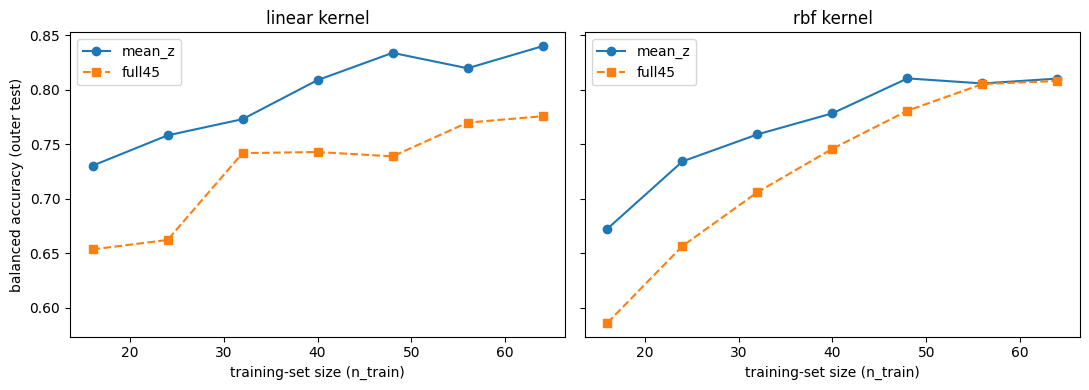

In [27]:
try:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    for ax, kn in zip(axes, ['linear', 'rbf']):
        for rep_name, style in [('mean_z', '-o'), ('full45', '--s')]:
            sub = lc_table[(lc_table.representation == rep_name) & (lc_table.model == kn)]
            ax.plot(sub.train_size, sub['mean'], style, label=rep_name)
        ax.set_title(f'{kn} kernel')
        ax.set_xlabel('training-set size (n_train)')
        ax.legend()
    axes[0].set_ylabel('balanced accuracy (outer test)')
    plt.tight_layout()
    plt.savefig(f'{OUTDIR}/exp9_learning_curves.png', dpi=120)
    plt.show()
except ImportError:
    print('matplotlib not available -- see exp9_learning_curves.csv for the numbers')

## Diagnostic 9: Selection-aware null test

Permutes the class labels 1000 times and asks how often the gap between `mean_z` and each control representation (random projections, PCA, the full
45 z-values, the 20-dimensional frequency vector) matches or exceeds the real gap. The hyperparameters used inside the permutation loop are the modal
ones from an honest nested CV, which is run first.

*Source: `EXPERIMENT_10`. The next cells hold its own definitions, kept as they were.*

In [28]:
N_PERMUTATIONS = 1000


In [29]:
def mean_from_full45(X45, exclude_positions=()):
    keep = [p for p in range(9) if p not in exclude_positions]
    out = np.zeros((X45.shape[0], 5))
    for k in range(5):
        cols = [p * 5 + k for p in keep]
        out[:, k] = X45[:, cols].mean(axis=1)
    return out


mean_z = mean_from_full45(full45)

AAS = sorted(set(''.join(sequences)))
comp_freq_20 = np.zeros((n_pep, len(AAS)))
for i, s in enumerate(sequences):
    for a in s:
        comp_freq_20[i, AAS.index(a)] += 1
comp_freq_20 /= len(sequences[0])


def make_random_projection(n_features_in, n_out=5, seed=2026):
    rng = np.random.default_rng(seed)
    return rng.normal(size=(n_features_in, n_out)) / np.sqrt(n_features_in)


N_RAND_PROJECTIONS = 5
RAND_SEEDS = {i: 2025 + i for i in range(1, N_RAND_PROJECTIONS + 1)}
RAND_Rs = {i: make_random_projection(45, 5, seed=RAND_SEEDS[i]) for i in RAND_SEEDS}
RAND_PROJ_NAMES = [f'rand_proj_{i}' for i in range(1, N_RAND_PROJECTIONS + 1)]
print('random projection seeds:', RAND_SEEDS)


def fit_scale(X_train, X_test):
    scaler = MinMaxScaler(feature_range=(-np.pi, np.pi))
    scaler.fit(X_train)
    return scaler.transform(X_train), scaler.transform(X_test)


def transform_random_projection(X_train, X_test, R):
    mu, sd = X_train.mean(0), X_train.std(0)
    sd = np.where(sd < 1e-12, 1.0, sd)
    return ((X_train - mu) / sd) @ R, ((X_test - mu) / sd) @ R


def transform_pca(X_train, X_test, n_components=5):
    scaler = StandardScaler().fit(X_train)
    pca = PCA(n_components=n_components, random_state=RANDOM_SEED).fit(scaler.transform(X_train))
    return pca.transform(scaler.transform(X_train)), pca.transform(scaler.transform(X_test))


def _transform(rep, tr_idx, te_idx):
    if callable(rep):
        return rep(tr_idx, te_idx)
    return fit_scale(rep[tr_idx], rep[te_idx])


REPS = {'mean_z': mean_z, 'comp_freq_20': comp_freq_20, 'full45': full45,
       'pca_5': lambda tr, te: transform_pca(full45[tr], full45[te], n_components=5)}
for i, R in RAND_Rs.items():
    REPS[f'rand_proj_{i}'] = (lambda tr, te, R=R: transform_random_projection(full45[tr], full45[te], R))

ALL_REP_NAMES = ['mean_z', 'comp_freq_20'] + RAND_PROJ_NAMES + ['pca_5', 'full45']
print(f'{len(ALL_REP_NAMES)} representations:', ALL_REP_NAMES)

random projection seeds: {1: 2026, 2: 2027, 3: 2028, 4: 2029, 5: 2030}
9 representations: ['mean_z', 'comp_freq_20', 'rand_proj_1', 'rand_proj_2', 'rand_proj_3', 'rand_proj_4', 'rand_proj_5', 'pca_5', 'full45']


In [30]:
def make_outer_splits(y, groups=None, n_splits=N_SPLITS_OUTER, n_repeats=N_REPEATS_OUTER,
                      random_state=RANDOM_SEED):
    if groups is None:
        return list(RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats,
                                            random_state=random_state).split(np.zeros(len(y)), y))
    splits = []
    for r in range(n_repeats):
        sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=random_state + r)
        splits.extend(sgkf.split(np.zeros(len(y)), y, groups))
    return splits


def _inner_splits(y_tr, groups_tr, fold_i):
    if groups_tr is None:
        return list(StratifiedKFold(n_splits=N_SPLITS_INNER, shuffle=True,
                                    random_state=RANDOM_SEED + fold_i).split(np.zeros(len(y_tr)), y_tr))
    return list(StratifiedGroupKFold(n_splits=N_SPLITS_INNER, shuffle=True,
                                     random_state=RANDOM_SEED + fold_i)
                .split(np.zeros(len(y_tr)), y_tr, groups_tr))


def _param_combinations(grid):
    keys = list(grid)
    return [dict(zip(keys, vals)) for vals in itertools.product(*(grid[k] for k in keys))]


def _resolve_gamma(gamma, Xs):
    if gamma == 'scale':
        return 1.0 / (Xs.shape[1] * Xs.var()) if Xs.var() > 0 else 1.0
    return gamma


def _fit_svc(kernel_name, Xtr, ytr, params):
    gamma = _resolve_gamma(params.get('gamma', 'scale'), Xtr)
    if kernel_name == 'linear':
        clf = SVC(kernel='linear', C=params['C'])
    elif kernel_name == 'rbf':
        clf = SVC(kernel='rbf', C=params['C'], gamma=gamma)
    else:
        clf = SVC(kernel='poly', C=params['C'], degree=params['degree'], gamma=gamma, coef0=params['coef0'])
    return clf.fit(Xtr, ytr)


def nested_cv_classical(rep, y, kernel_name, groups=None, n_repeats_outer=N_REPEATS_OUTER):
    combos = _param_combinations(CLASSICAL_GRIDS[kernel_name])
    outer = make_outer_splits(y, groups, n_repeats=n_repeats_outer)
    rows, predictions = [], {}

    for fold_i, (tr_idx, te_idx) in enumerate(outer):
        y_tr, y_te = y[tr_idx], y[te_idx]
        inner = _inner_splits(y_tr, None if groups is None else groups[tr_idx], fold_i)

        inner_scores = {}
        for in_tr, in_val in inner:
            abs_tr, abs_val = tr_idx[in_tr], tr_idx[in_val]
            Xi_tr, Xi_val = _transform(rep, abs_tr, abs_val)
            for ci, params in enumerate(combos):
                clf = _fit_svc(kernel_name, Xi_tr, y[abs_tr], params)
                s = balanced_accuracy_score(y[abs_val], clf.predict(Xi_val))
                inner_scores.setdefault(ci, []).append(s)

        best_ci = max(inner_scores, key=lambda k: np.mean(inner_scores[k]))
        best_params = combos[best_ci]

        Xtr, Xte = _transform(rep, tr_idx, te_idx)
        clf = _fit_svc(kernel_name, Xtr, y_tr, best_params)
        y_pred = clf.predict(Xte)

        row = {'fold': fold_i, 'balanced_accuracy': balanced_accuracy_score(y_te, y_pred),
               'n_train': len(tr_idx), 'n_test': len(te_idx)}
        row.update({f'best_{k}': v for k, v in best_params.items()})
        rows.append(row)
        predictions[fold_i] = {'test_idx': te_idx.tolist(), 'y_true': y_te.tolist(), 'y_pred': y_pred.tolist()}
    return pd.DataFrame(rows), predictions

### 9.1 Honest nested CV (real numbers and modal hyperparameters)

In [31]:
t0 = time.time()
honest_results = {}
for rep_name in ALL_REP_NAMES:
    honest_results[rep_name] = {}
    for kn in MODELS:
        res, preds = nested_cv_classical(REPS[rep_name], y, kn, groups=groups)
        honest_results[rep_name][kn] = (res, preds)
    print(f'  {rep_name}: {time.time()-t0:.0f}s elapsed')
print(f'Honest nested CV total: {time.time()-t0:.0f}s')

tab = pd.DataFrame({rep_name: {kn: honest_results[rep_name][kn][0]['balanced_accuracy'].mean()
                               for kn in MODELS}
                    for rep_name in ALL_REP_NAMES}).T
tab.to_csv(f'{OUTDIR}/exp10_honest_balanced_accuracy.csv')
display(tab)

  mean_z: 34s elapsed
  comp_freq_20: 65s elapsed
  rand_proj_1: 98s elapsed
  rand_proj_2: 131s elapsed
  rand_proj_3: 163s elapsed
  rand_proj_4: 196s elapsed
  rand_proj_5: 228s elapsed
  pca_5: 297s elapsed
  full45: 327s elapsed
Honest nested CV total: 327s


,linear,rbf,poly
mean_z,0.832806,0.804961,0.831382
comp_freq_20,0.779122,0.784439,0.795056
rand_proj_1,0.606480,0.682410,0.691622
rand_proj_2,0.489384,0.507652,0.523793
rand_proj_3,0.594891,0.593480,0.555567
rand_proj_4,0.562217,0.680183,0.585039
rand_proj_5,0.584846,0.625664,0.577398
pca_5,0.638938,0.617038,0.577622
full45,0.755062,0.792241,0.769870


In [32]:
def extract_modal_params(res_by_model):
    out = {}
    for kn, (res, preds) in res_by_model.items():
        if kn == 'linear':
            out[kn] = {'C': res['best_C'].mode()[0]}
        elif kn == 'rbf':
            out[kn] = {'C': res['best_C'].mode()[0], 'gamma': res['best_gamma'].mode()[0]}
        else:
            out[kn] = {'C': res['best_C'].mode()[0], 'gamma': res['best_gamma'].mode()[0],
                      'degree': res['best_degree'].mode()[0], 'coef0': res['best_coef0'].mode()[0]}
    return out


modal_params = {rep_name: extract_modal_params(honest_results[rep_name]) for rep_name in ALL_REP_NAMES}
for rep_name, by_kernel in modal_params.items():
    print(f'{rep_name:14s}', by_kernel)

mean_z         {'linear': {'C': 1.0}, 'rbf': {'C': 10, 'gamma': 0.01}, 'poly': {'C': 1.0, 'gamma': 'scale', 'degree': 2, 'coef0': 1.0}}
comp_freq_20   {'linear': {'C': 0.1}, 'rbf': {'C': 10, 'gamma': 0.01}, 'poly': {'C': 0.1, 'gamma': 'scale', 'degree': 3, 'coef0': 0.0}}
rand_proj_1    {'linear': {'C': 1.0}, 'rbf': {'C': 10, 'gamma': 0.1}, 'poly': {'C': 1.0, 'gamma': 'scale', 'degree': 2, 'coef0': 1.0}}
rand_proj_2    {'linear': {'C': 0.1}, 'rbf': {'C': 10.0, 'gamma': 0.1}, 'poly': {'C': 1.0, 'gamma': 1, 'degree': 2, 'coef0': 0.0}}
rand_proj_3    {'linear': {'C': 0.1}, 'rbf': {'C': 1, 'gamma': 0.1}, 'poly': {'C': 1.0, 'gamma': 1, 'degree': 2, 'coef0': 1.0}}
rand_proj_4    {'linear': {'C': 1.0}, 'rbf': {'C': 10, 'gamma': 1}, 'poly': {'C': 1.0, 'gamma': 1, 'degree': 3, 'coef0': 1.0}}
rand_proj_5    {'linear': {'C': 0.1}, 'rbf': {'C': 10, 'gamma': 0.1}, 'poly': {'C': 10.0, 'gamma': 'scale', 'degree': 3, 'coef0': 1.0}}
pca_5          {'linear': {'C': 1.0}, 'rbf': {'C': 1.0, 'gamma': 'scale

### 9.2 Permutation loop

In [33]:
def _fit_svc_fixed(kernel_name, Xtr, ytr, params):
    if kernel_name == 'linear':
        return SVC(kernel='linear', C=params['C']).fit(Xtr, ytr)
    gamma = params['gamma']
    if gamma == 'scale':
        gamma = 1.0 / (Xtr.shape[1] * Xtr.var()) if Xtr.var() > 0 else 1.0
    if kernel_name == 'rbf':
        return SVC(kernel='rbf', C=params['C'], gamma=gamma).fit(Xtr, ytr)
    return SVC(kernel='poly', C=params['C'], degree=params['degree'], gamma=gamma,
              coef0=params['coef0']).fit(Xtr, ytr)


def quick_cv_score(X, y_perm, groups, kernel_name, params, n_splits=5, seed=0):
    skf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    scores = []
    for tr, te in skf.split(np.zeros(len(y_perm)), y_perm, groups):
        Xtr, Xte = fit_scale(X[tr], X[te])
        clf = _fit_svc_fixed(kernel_name, Xtr, y_perm[tr], params)
        scores.append(balanced_accuracy_score(y_perm[te], clf.predict(Xte)))
    return np.mean(scores)


def null_representations(full45_local, comp_freq_20_local, mean_z_local, Rs, seed_for_pca=RANDOM_SEED):
    out = {'mean_z': mean_z_local, 'comp_freq_20': comp_freq_20_local, 'full45': full45_local}
    for rp_name, R in Rs.items():
        out[rp_name] = ((full45_local - full45_local.mean(0)) / full45_local.std(0)) @ R
    out['pca_5'] = PCA(n_components=5, random_state=seed_for_pca).fit_transform(
        StandardScaler().fit_transform(full45_local))
    return out


RAND_Rs_by_name = {f'rand_proj_{i}': R for i, R in RAND_Rs.items()}
NULL_REPS = [r for r in ALL_REP_NAMES if r != 'mean_z']

In [34]:
rng_perm = np.random.default_rng(RANDOM_SEED)
null_gaps = {kn: {rep: [] for rep in NULL_REPS} for kn in MODELS}

t0 = time.time()
for p in range(N_PERMUTATIONS):
    y_perm = rng_perm.permutation(y)
    null_reps_p = null_representations(full45, comp_freq_20, mean_z, RAND_Rs_by_name,
                                       seed_for_pca=RANDOM_SEED)
    scores_p = {}
    for rep_name in ALL_REP_NAMES:
        for kn in MODELS:
            scores_p[(rep_name, kn)] = quick_cv_score(
                null_reps_p[rep_name], y_perm, groups, kn, modal_params[rep_name][kn], seed=p)
    for kn in MODELS:
        for rep_name in NULL_REPS:
            null_gaps[kn][rep_name].append(scores_p[('mean_z', kn)] - scores_p[(rep_name, kn)])
    if (p + 1) % 200 == 0:
        print(f'  {p+1}/{N_PERMUTATIONS} permutations, {time.time()-t0:.0f}s')

print(f'Null test: {time.time()-t0:.0f}s total for {N_PERMUTATIONS} permutations, '
      f'{len(NULL_REPS)} representations x {len(MODELS)} kernels')

  200/1000 permutations, 125s


/home/luispabloelchido/miniconda3/envs/QML/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/luispabloelchido/miniconda3/envs/QML/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/luispabloelchido/miniconda3/envs/QML/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/luispabloelchido/miniconda3/envs/QML/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/luispabloelchido/miniconda3/envs/QML/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: Use

  400/1000 permutations, 249s
  600/1000 permutations, 373s
  800/1000 permutations, 498s


/home/luispabloelchido/miniconda3/envs/QML/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/luispabloelchido/miniconda3/envs/QML/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/luispabloelchido/miniconda3/envs/QML/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/luispabloelchido/miniconda3/envs/QML/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/luispabloelchido/miniconda3/envs/QML/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: Use

  1000/1000 permutations, 622s
Null test: 622s total for 1000 permutations, 8 representations x 3 kernels


### 9.3 Results

In [35]:
observed_gaps = {}
for kn in MODELS:
    for rep_name in NULL_REPS:
        observed_gaps[(kn, rep_name)] = tab.loc['mean_z', kn] - tab.loc[rep_name, kn]

rows = []
for kn in MODELS:
    for rep_name in NULL_REPS:
        null = np.array(null_gaps[kn][rep_name])
        obs = observed_gaps[(kn, rep_name)]
        p_emp = (null >= obs).mean()
        rows.append({'kernel': kn, 'vs': rep_name, 'observed_gap': obs,
                    'null_mean': null.mean(), 'null_std': null.std(),
                    'null_97.5pct': np.percentile(null, 97.5),
                    'empirical_p_one_sided': p_emp})

null_summary = pd.DataFrame(rows).set_index(['kernel', 'vs'])
null_summary.to_csv(f'{OUTDIR}/exp10_null_test.csv')
display(null_summary)

observed_gap  null_mean  null_std  null_97.5pct  \
kernel vs                                                              
linear comp_freq_20      0.053684  -0.001377  0.082071      0.155836   
       rand_proj_1       0.226326  -0.000556  0.094608      0.180426   
       rand_proj_2       0.343423  -0.000018  0.092962      0.177710   
       rand_proj_3       0.237916   0.000889  0.089586      0.174119   
       rand_proj_4       0.270589  -0.002322  0.094972      0.176896   
       rand_proj_5       0.247960   0.001118  0.094364      0.185965   
       pca_5             0.193869   0.001148  0.089092      0.181577   
       full45            0.077744  -0.000103  0.088964      0.161876   
rbf    comp_freq_20      0.020522   0.000917  0.084207      0.172651   
       rand_proj_1       0.122550  -0.002845  0.095983      0.179508   
       rand_proj_2       0.297309  -0.000189  0.096865      0.181756   
       rand_proj_3       0.211481   0.000284  0.091157      0.183119   
       rand_proj_4       0.124777  -0.002190  0.089565      0.179715   
       rand_proj_5       0.179297  -0.001389  0.090083      0.172850   
       pca_5             0.187923   0.002114  0.088011      0.177194   
       full45            0.012720   0.003351  0.084089      0.165495   
poly   comp_freq_20      0.036326   0.000140  0.086932      0.165820   
       rand_proj_1       0.139759  -0.005376  0.097299      0.192327   
       rand_proj_2       0.307589  -0.000696  0.098730      0.193484   
       rand_proj_3       0.275814  -0.001569  0.095259      0.190936   
       rand_proj_4       0.246342  -0.000327  0.094405      0.181777   
       rand_proj_5       0.253983  -0.002915  0.095501      0.190506   
       pca_5             0.253760   0.001608  0.093783      0.189662   
       full45            0.061511   0.003662  0.090025      0.176740   

                     empirical_p_one_sided  
kernel vs                                   
linear comp_freq_20                  0.256  
       rand_proj_1                   0.006  
       rand_proj_2                   0.000  
       rand_proj_3                   0.005  
       rand_proj_4                   0.003  
       rand_proj_5                   0.004  
       pca_5                         0.017  
       full45                        0.198  
rbf    comp_freq_20                  0.396  
       rand_proj_1                   0.096  
       rand_proj_2                   0.002  
       rand_proj_3                   0.011  
       rand_proj_4                   0.083  
       rand_proj_5                   0.023  
       pca_5                         0.016  
       full45                        0.460  
poly   comp_freq_20                  0.353  
       rand_proj_1                   0.077  
       rand_proj_2                   0.000  
       rand_proj_3                   0.001  
       rand_proj_4                   0.006  
       rand_proj_5                   0.002  
       pca_5                         0.004  
       full45                        0.260

In [36]:
pooled_rows = []
for kn in MODELS:
    pooled_null = np.concatenate([null_gaps[kn][rp] for rp in RAND_PROJ_NAMES])
    pooled_obs_mean = np.mean([observed_gaps[(kn, rp)] for rp in RAND_PROJ_NAMES])
    p_emp_pooled = (pooled_null >= pooled_obs_mean).mean()
    pooled_rows.append({'kernel': kn, 'mean_observed_gap_across_5_draws': pooled_obs_mean,
                        'pooled_null_mean': pooled_null.mean(), 'pooled_null_std': pooled_null.std(),
                        'empirical_p_pooled_across_draws': p_emp_pooled})
pooled_summary = pd.DataFrame(pooled_rows).set_index('kernel')
pooled_summary.to_csv(f'{OUTDIR}/exp10_null_test_pooled_randproj.csv')
print('mean_z vs "random projections in general" (5 draws pooled together):')
display(pooled_summary)

mean_z vs "random projections in general" (5 draws pooled together):


,mean_observed_gap_across_5_draws,pooled_null_mean,pooled_null_std,empirical_p_pooled_across_draws
kernel,,,,
linear,0.265243,-0.000178,0.093327,0.0016
rbf,0.187083,-0.001266,0.092789,0.0210
poly,0.244698,-0.002176,0.096269,0.0040


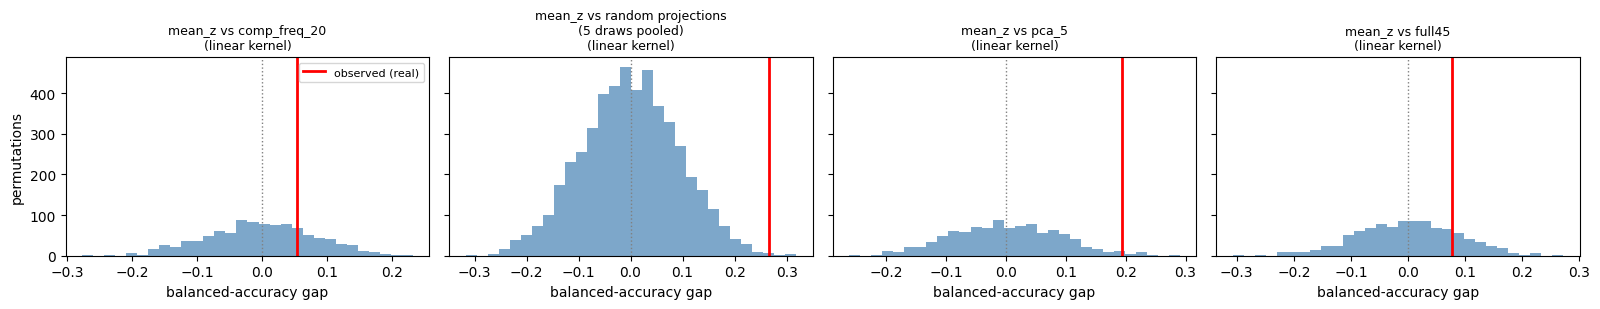

In [37]:
try:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.2), sharey=True)
    pooled_null_linear = np.concatenate([null_gaps['linear'][rp] for rp in RAND_PROJ_NAMES])
    panels = [('comp_freq_20', null_gaps['linear']['comp_freq_20'],
              observed_gaps[('linear', 'comp_freq_20')], 'mean_z vs comp_freq_20'),
             ('rand_proj (5 draws pooled)', pooled_null_linear,
              np.mean([observed_gaps[('linear', rp)] for rp in RAND_PROJ_NAMES]),
              'mean_z vs random projections\n(5 draws pooled)'),
             ('pca_5', null_gaps['linear']['pca_5'],
              observed_gaps[('linear', 'pca_5')], 'mean_z vs pca_5'),
             ('full45', null_gaps['linear']['full45'],
              observed_gaps[('linear', 'full45')], 'mean_z vs full45')]
    for ax, (_, null_vals, obs_val, title) in zip(axes, panels):
        ax.hist(null_vals, bins=30, alpha=0.7, color='steelblue')
        ax.axvline(obs_val, color='red', lw=2, label='observed (real)')
        ax.axvline(0, color='gray', lw=1, ls=':')
        ax.set_title(f'{title}\n(linear kernel)', fontsize=9)
        ax.set_xlabel('balanced-accuracy gap')
    axes[0].set_ylabel('permutations')
    axes[0].legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(f'{OUTDIR}/exp10_null_distributions.png', dpi=120)
    plt.show()
except ImportError:
    print('matplotlib not available -- see exp10_null_test.csv for the numbers')